# Лабораторная работа №1. Регрессия

**Задача:** предсказать качество вина (`quality`) по его физико-химическим характеристикам.

**Датасет:** [Wine Quality (UCI)](https://archive.ics.uci.edu/dataset/186/wine+quality) — красные и белые португальские вина «Vinho Verde».

**Основная метрика:** RMSE, дополнительная — MAE.

План работы:
1. Загрузка данных
2. Разведочный анализ (EDA)
3. Разбиение на train / test
4. Бейзлайн
5. Метрики
6. Модели: линейная регрессия, случайный лес, градиентный бустинг
7. Сравнение моделей
8. Важность признаков
9. Анализ ошибок лучшей модели
10. Выводы

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

sns.set(style='whitegrid')
RANDOM_STATE = 42

## 1. Загрузка данных

В датасете два файла: красные вина (1599 штук) и белые (4898 штук). Разделитель в файлах — `;`.
Я объединяю их в одну таблицу и добавляю признак `is_red` (1 — красное, 0 — белое), чтобы модель знала, какой это тип вина.

Если файлы уже скачаны и лежат рядом с ноутбуком, они читаются локально, иначе — скачиваются с сайта UCI.

In [4]:
import os

URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/'

def load_wine(name):
    file = f'winequality-{name}.csv'
    if os.path.exists(file):
        return pd.read_csv(file, sep=';')
    return pd.read_csv(URL + file, sep=';')

red = load_wine('red')
white = load_wine('white')

red['is_red'] = 1
white['is_red'] = 0

df = pd.concat([red, white], ignore_index=True)
print('Красных вин:', red.shape[0])
print('Белых вин:', white.shape[0])
print('Всего:', df.shape)
df.head()

Красных вин: 1599
Белых вин: 4898
Всего: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


## 2. Разведочный анализ данных (EDA)

### 2.1 Общая информация

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [6]:
print('Пропусков в данных:', df.isna().sum().sum())
print('Полных дубликатов строк:', df.duplicated().sum())

Пропусков в данных: 0
Полных дубликатов строк: 1177


**Вывод:** все признаки числовые, пропусков нет, поэтому заполнять ничего не нужно.
В данных есть дубликаты (одинаковые строки). Скорее всего, это вина, у которых случайно совпали все измерения
(или одно и то же вино попало в выборку несколько раз). Я их не удаляю, потому что в скрытом тесте данные, скорее всего,
устроены так же. Но нужно помнить, что из-за дубликатов одинаковые строки могут попасть и в train, и в test,
и это немного завышает качество моделей, которые хорошо «запоминают» данные (например, случайный лес).

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


**Вывод:** признаки имеют очень разный масштаб: например, `density` около 1 и меняется в третьем знаке после запятой,
а `total sulfur dioxide` — десятки и сотни. Для линейной регрессии это значит, что признаки нужно
**масштабировать** (иначе коэффициенты нельзя сравнивать между собой). Для деревьев масштабирование не важно.

У некоторых признаков (`residual sugar`, `chlorides`, `free sulfur dioxide`) максимум намного больше 75%-квантиля — есть выбросы.

### 2.2 Целевая переменная `quality`

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

Доля каждого значения:
quality
3    0.005
4    0.033
5    0.329
6    0.437
7    0.166
8    0.030
9    0.001
Name: count, dtype: float64


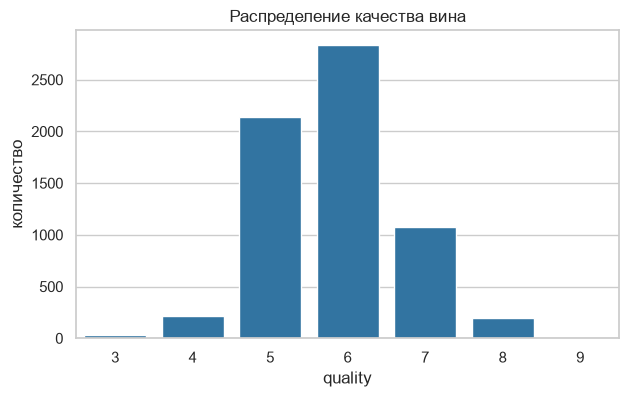

In [8]:
counts = df['quality'].value_counts().sort_index()
print(counts)
print()
print('Доля каждого значения:')
print((counts / len(df)).round(3))

plt.figure(figsize=(7, 4))
sns.countplot(x='quality', data=df, color='tab:blue')
plt.title('Распределение качества вина')
plt.xlabel('quality')
plt.ylabel('количество')
plt.show()

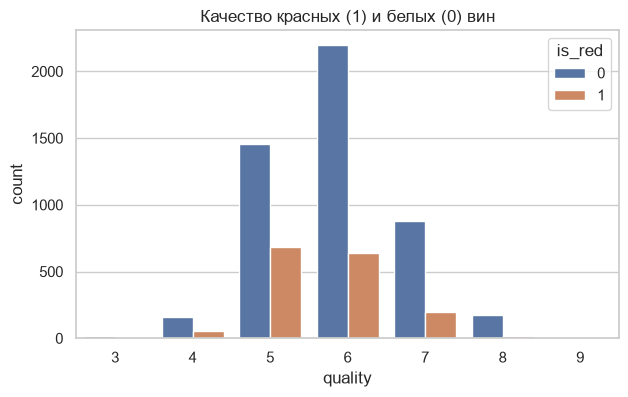

Среднее качество:
is_red
0    5.877909
1    5.636023
Name: quality, dtype: float64


In [9]:
plt.figure(figsize=(7, 4))
sns.countplot(x='quality', hue='is_red', data=df)
plt.title('Качество красных (1) и белых (0) вин')
plt.show()

print('Среднее качество:')
print(df.groupby('is_red')['quality'].mean())

**Вывод:**
- Оценки качества — целые числа от 3 до 9, но на практике почти все вина имеют оценку **5, 6 или 7**.
- Классы очень несбалансированные: оценок 3, 4, 8 и 9 мало (а оценка 9 — вообще всего несколько вин).
  Поэтому модели будет трудно научиться предсказывать крайние значения, и на них ошибка, скорее всего, будет больше.
- Из-за такого распределения при разбиении на train/test я буду делать **стратификацию по quality**,
  чтобы редкие оценки попали в обе части в одинаковой пропорции.
- Среднее качество белых и красных вин немного отличается, поэтому признак `is_red` может быть полезным.

### 2.3 Распределения признаков

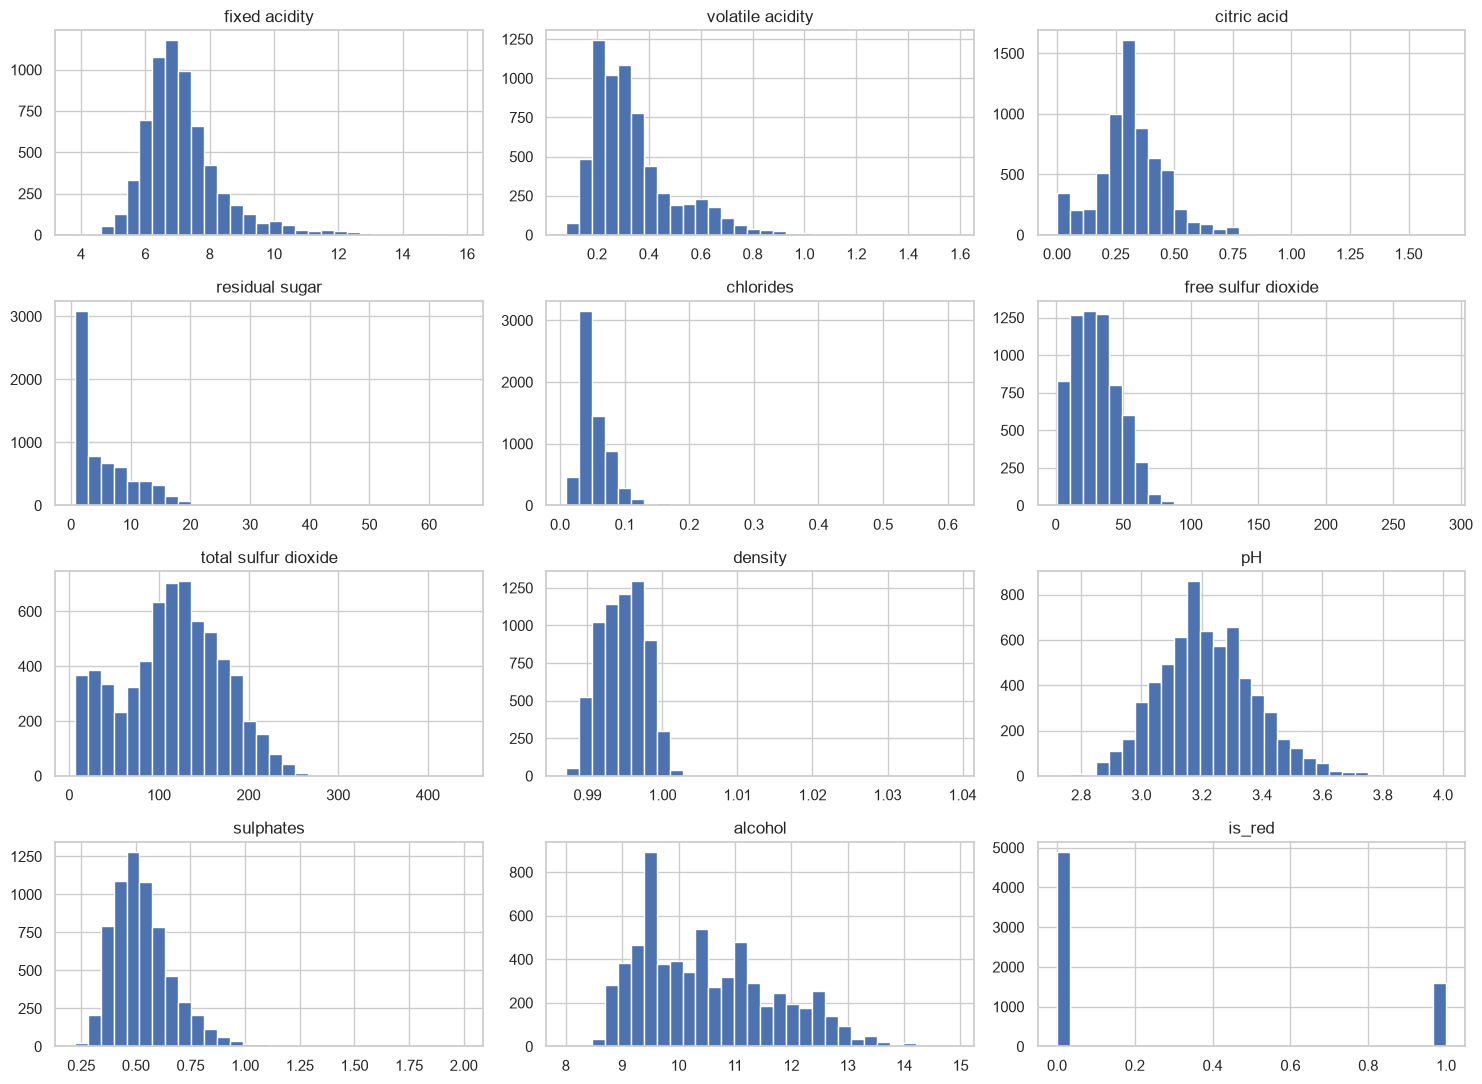

In [10]:
features = df.columns.drop('quality')

df[features].hist(bins=30, figsize=(15, 11))
plt.tight_layout()
plt.show()

**Вывод:** многие признаки имеют несимметричное распределение с длинным правым хвостом
(`residual sugar`, `chlorides`, `free sulfur dioxide`, `sulphates`). Это значит, что есть небольшое количество вин
с очень большими значениями. Для линейной регрессии такие выбросы могут сильно влиять на коэффициенты,
а деревья к ним устойчивее.

### 2.4 Корреляции

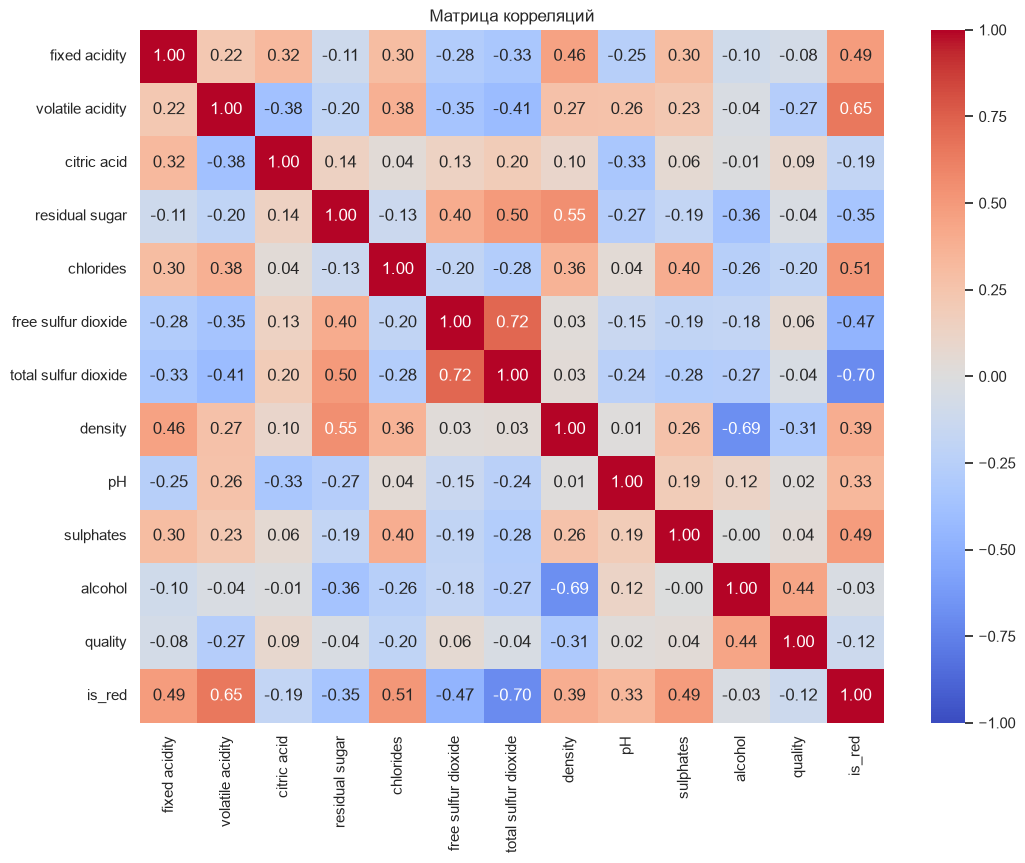

In [11]:
corr = df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Матрица корреляций')
plt.show()

density                -0.306
volatile acidity       -0.266
chlorides              -0.201
is_red                 -0.119
fixed acidity          -0.077
total sulfur dioxide   -0.041
residual sugar         -0.037
pH                      0.020
sulphates               0.038
free sulfur dioxide     0.055
citric acid             0.086
alcohol                 0.444
Name: quality, dtype: float64


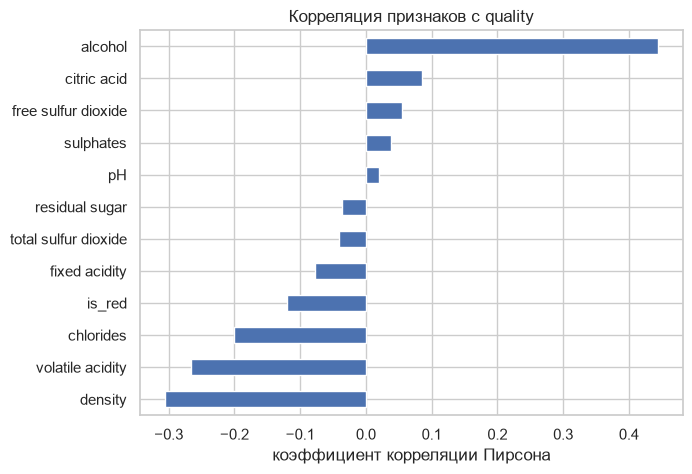

In [12]:
corr_with_target = corr['quality'].drop('quality').sort_values()
print(corr_with_target.round(3))

plt.figure(figsize=(7, 5))
corr_with_target.plot(kind='barh')
plt.title('Корреляция признаков с quality')
plt.xlabel('коэффициент корреляции Пирсона')
plt.show()

**Вывод:**
- Сильнее всего с качеством связан **`alcohol`** (корреляция около 0.44, положительная): чем больше алкоголя, тем в среднем выше оценка.
  Для моделирования это значит, что `alcohol` — самый информативный признак, и любая разумная модель должна его использовать.
  Но корреляция всего 0.44, то есть один алкоголь объясняет качество далеко не полностью — нужны и другие признаки.
- Отрицательно с качеством связаны `density`, `volatile acidity` (летучая кислотность, «уксусный» привкус) и `chlorides`.
- Многие признаки почти не коррелируют с качеством (`pH`, `sulphates`, `residual sugar` и т.д.). Но корреляция Пирсона
  показывает только **линейную** связь, поэтому нелинейная зависимость может быть, и деревья могут её найти.
- Есть сильно связанные между собой признаки: `density` и `alcohol` (около −0.7), `density` и `residual sugar`,
  `free` и `total sulfur dioxide`. Это **мультиколлинеарность** — из-за неё коэффициенты линейной регрессии
  могут быть неустойчивыми, и их нельзя напрямую трактовать как «вклад» признака.

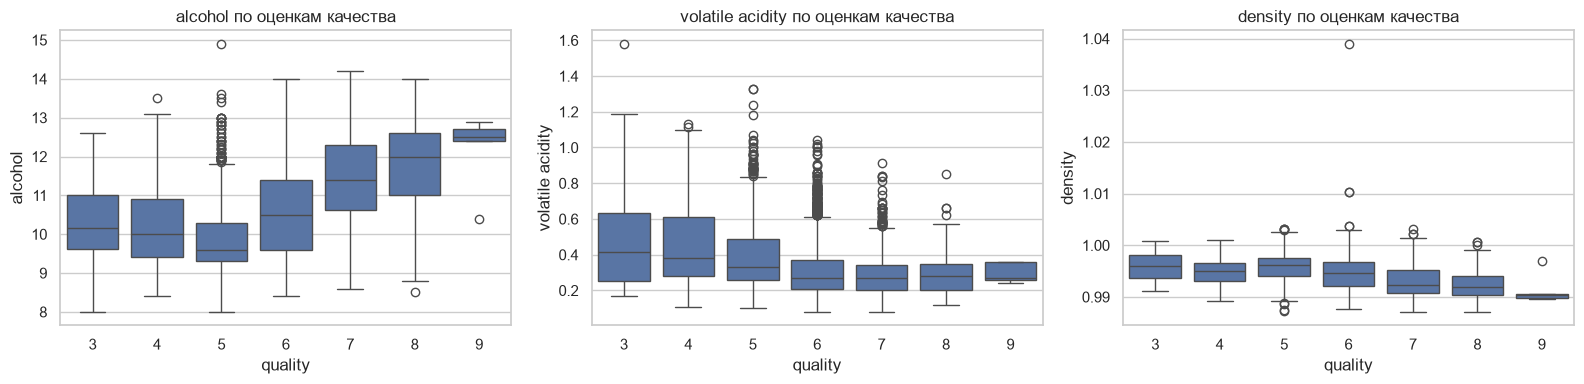

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['alcohol', 'volatile acidity', 'density']):
    sns.boxplot(x='quality', y=col, data=df, ax=ax)
    ax.set_title(f'{col} по оценкам качества')
plt.tight_layout()
plt.show()

**Вывод:** по boxplot'ам хорошо видно, что медиана `alcohol` растёт с ростом качества (особенно начиная с 5),
а `volatile acidity` наоборот уменьшается. При этом «ящики» соседних оценок сильно перекрываются — то есть
вина с одинаковым алкоголем могут иметь разные оценки. Значит, идеально предсказать качество не получится,
ошибка порядка половины балла — нормальный результат.

## 3. Разбиение на train и test

- `X` — все признаки, кроме `quality` (целевую переменную **обязательно** убираем из признаков).
- Разбиваю 80% / 20% с фиксированным `random_state=42`, чтобы результат был воспроизводимым.
- Использую **стратификацию** по `quality`, чтобы распределение оценок в train и test было одинаковым
  (иначе редкие оценки 3, 8, 9 могли бы почти целиком попасть только в одну часть).

In [14]:
X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Train:', X_train.shape)
print('Test: ', X_test.shape)
print()
print(pd.DataFrame({
    'train': y_train.value_counts(normalize=True).sort_index().round(3),
    'test': y_test.value_counts(normalize=True).sort_index().round(3)
}))

Train: (5197, 12)
Test:  (1300, 12)

         train   test
quality              
3        0.005  0.005
4        0.033  0.033
5        0.329  0.329
6        0.437  0.436
7        0.166  0.166
8        0.030  0.030
9        0.001  0.001


**Почему так:**
- **Размеры:** в train около 5200 объектов, в test около 1300. 20% — достаточно, чтобы оценка метрики на тесте была
  стабильной, и при этом для обучения остаётся большая часть данных.
- **Почему случайное разбиение со стратификацией:** у нас нет временной структуры (вина не упорядочены по дате),
  поэтому подходит обычное случайное разбиение. Стратификация нужна из-за несбалансированных оценок.
- **Почему нельзя много раз смотреть на один и тот же test:** если я буду подбирать модель и гиперпараметры по тесту,
  то я фактически «обучусь» на тесте — выберу то, что случайно хорошо сработало именно на этих 1300 винах.
  Оценка станет слишком оптимистичной, и на новых данных (скрытом тесте) результат будет хуже.
  Поэтому все решения (сравнение вариантов, гиперпараметры) я принимаю по **кросс-валидации на train**,
  а test использую только один раз — для финальной оценки.
- Масштабирование (`StandardScaler`) я обучаю **только на train** — для этого использую `Pipeline`.
  Если обучить scaler на всём датасете, то среднее и дисперсия теста «просочатся» в обучение (утечка данных).

## 4. Метрики

$$RMSE = \sqrt{\frac{1}{n}\sum (y_i - \hat y_i)^2}, \qquad MAE = \frac{1}{n}\sum |y_i - \hat y_i|$$

- **MAE** — средняя абсолютная ошибка: на сколько баллов в среднем модель ошибается. Её легко интерпретировать.
- **RMSE** — корень из средней квадратичной ошибки. Измеряется в тех же единицах (баллах), что и `quality`.
- **Почему RMSE сильнее реагирует на большие ошибки:** ошибки возводятся в квадрат. Ошибка в 2 балла даёт вклад 4,
  а ошибка в 0.5 — всего 0.25. То есть одна большая ошибка «весит» как 16 маленьких. В MAE ошибка 2 весит только в 4 раза больше, чем 0.5.
- **Почему они отличаются:** всегда RMSE ≥ MAE. Чем сильнее разброс ошибок (чем больше крупных промахов),
  тем больше разница между RMSE и MAE. Если бы все ошибки были одинаковыми по модулю, метрики совпали бы.

Для нашей задачи RMSE — основная метрика (и порог в задании дан для RMSE): нам важно, чтобы модель не делала
грубых ошибок, например не ставила вину с оценкой 8 оценку 5.

In [15]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

results = []  # сюда буду складывать результаты всех моделей

def evaluate(name, y_true, y_pred):
    r = rmse(y_true, y_pred)
    m = mean_absolute_error(y_true, y_pred)
    results.append({'Модель': name, 'RMSE': r, 'MAE': m})
    print(f'{name}: RMSE = {r:.4f}, MAE = {m:.4f}')

# кросс-валидация на train (5 фолдов) — для сравнения моделей без использования теста
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_rmse(model):
    scores = cross_val_score(model, X_train, y_train, cv=kf,
                             scoring='neg_mean_squared_error')
    return np.sqrt(-scores).mean()

## 5. Бейзлайн

Самая простая модель — всегда предсказывать одно и то же число. Какое число выбрать?
Для **RMSE (MSE)** оптимальная константа — это **среднее** значение целевой переменной: именно среднее минимизирует
сумму квадратов отклонений (если взять производную $\sum (y_i - c)^2$ по $c$ и приравнять к нулю, получится $c = \bar y$).
(Для MAE оптимальной константой была бы медиана.)

Важно: среднее считаю **по train**, а не по всему датасету.

In [16]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
print('Константа (среднее quality на train):', round(baseline.constant_[0][0], 4))

y_pred_base = baseline.predict(X_test)
evaluate('Baseline (среднее)', y_test, y_pred_base)

Константа (среднее quality на train): 5.8182
Baseline (среднее): RMSE = 0.8738, MAE = 0.6861


**Вывод:** RMSE бейзлайна примерно равна стандартному отклонению `quality` (около 0.87). Это «нижняя планка»:
любая полезная модель должна давать ошибку меньше. Если модель не лучше бейзлайна — она ничему не научилась.

## 6. Модели

### 6.1 Линейная регрессия

Линейной регрессии нужно масштабирование, поэтому собираю `Pipeline`: `StandardScaler` → `LinearRegression`.
Pipeline гарантирует, что scaler обучается только на train (и внутри кросс-валидации — только на обучающих фолдах).

In [17]:
lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

print('CV RMSE на train:', round(cv_rmse(lr), 4))

lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
evaluate('Linear Regression', y_test, y_pred_lr)

CV RMSE на train: 0.7377
Linear Regression: RMSE = 0.7280, MAE = 0.5678


density                -0.323
volatile acidity       -0.242
total sulfur dioxide   -0.091
chlorides              -0.022
citric acid            -0.014
free sulfur dioxide     0.086
pH                      0.088
sulphates               0.109
fixed acidity           0.112
is_red                  0.134
alcohol                 0.256
residual sugar          0.309
dtype: float64


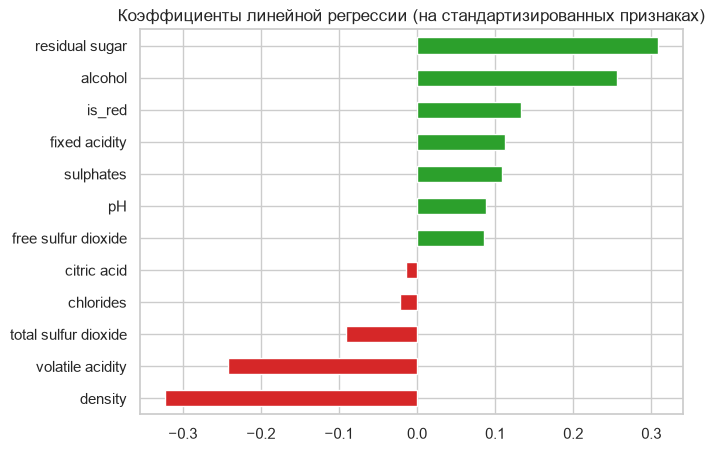

In [18]:
coefs = pd.Series(lr.named_steps['model'].coef_, index=X.columns).sort_values()
print(coefs.round(3))

plt.figure(figsize=(7, 5))
coefs.plot(kind='barh', color=['tab:red' if c < 0 else 'tab:green' for c in coefs])
plt.title('Коэффициенты линейной регрессии (на стандартизированных признаках)')
plt.show()

**Анализ коэффициентов:**
- Так как признаки стандартизированы, коэффициент показывает, на сколько баллов меняется предсказание,
  если признак увеличить на одно стандартное отклонение (при остальных признаках неизменными).
- Большие положительные коэффициенты обычно у `alcohol` и `residual sugar`, большой отрицательный — у `density`,
  отрицательный — у `volatile acidity`. Это в целом согласуется с EDA (алкоголь ↑ — качество ↑, летучая кислотность ↑ — качество ↓).
- **Почему коэффициенты нельзя трактовать напрямую:** признаки сильно коррелируют друг с другом
  (`density` почти полностью определяется `alcohol` и `residual sugar`). При мультиколлинеарности модель может
  «перераспределять» вес между связанными признаками, и коэффициенты становятся большими по модулю и неустойчивыми.
  Например, у `residual sugar` в EDA корреляция с качеством около нуля, а коэффициент может быть заметно положительным —
  он «компенсирует» `density`. Кроме того, коэффициенты показывают связь в рамках линейной модели, а не причину.
- Линейная модель лучше бейзлайна, но не сильно: зависимость качества от признаков не совсем линейная.

### 6.2 Случайный лес (Random Forest)

Случайный лес — это много решающих деревьев, каждое обучено на случайной подвыборке объектов и признаков,
а ответ — среднее по деревьям. Деревьям не нужно масштабирование, они умеют находить нелинейные зависимости
и взаимодействия признаков. Усреднение многих деревьев уменьшает переобучение отдельного дерева.

Сначала сравниваю пару вариантов гиперпараметров **по кросс-валидации на train** (не по тесту!).

In [19]:
rf_cv = {}
for n in [100, 300]:
    for max_features in [1.0, 'sqrt']:
        rf_try = RandomForestRegressor(n_estimators=n, max_features=max_features,
                                       random_state=RANDOM_STATE, n_jobs=-1)
        rf_cv[(n, max_features)] = cv_rmse(rf_try)
        print(f'n_estimators={n}, max_features={max_features}: CV RMSE = {rf_cv[(n, max_features)]:.4f}')

best_rf_params = min(rf_cv, key=rf_cv.get)
print('Лучшие параметры по CV:', best_rf_params)

n_estimators=100, max_features=1.0: CV RMSE = 0.6273
n_estimators=100, max_features=sqrt: CV RMSE = 0.6146
n_estimators=300, max_features=1.0: CV RMSE = 0.6236
n_estimators=300, max_features=sqrt: CV RMSE = 0.6130
Лучшие параметры по CV: (300, 'sqrt')


Беру вариант с наименьшей RMSE на кросс-валидации. Обычно лучше `max_features='sqrt'`
(каждое дерево видит только часть признаков, деревья получаются разнообразнее, и их среднее точнее),
а 300 деревьев чуть стабильнее, чем 100.

In [20]:
rf = RandomForestRegressor(n_estimators=best_rf_params[0], max_features=best_rf_params[1],
                           random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print('RMSE на train:', round(rmse(y_train, rf.predict(X_train)), 4))
evaluate('Random Forest', y_test, y_pred_rf)

RMSE на train: 0.2207
Random Forest: RMSE = 0.5932, MAE = 0.4247


**Про переобучение:** ошибка на train у случайного леса намного меньше, чем на test — деревья почти «запоминают»
обучающую выборку. Это нормально для случайного леса: важна именно ошибка на тесте, а она получается заметно
меньше, чем у линейной регрессии.

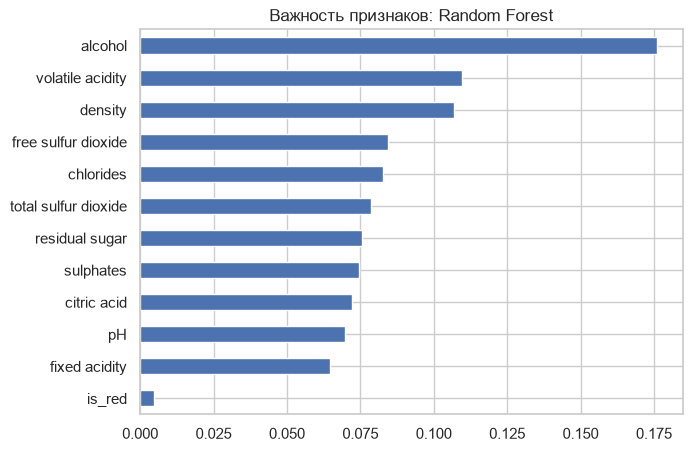

alcohol                 0.176
volatile acidity        0.110
density                 0.107
free sulfur dioxide     0.085
chlorides               0.083
total sulfur dioxide    0.079
residual sugar          0.076
sulphates               0.075
citric acid             0.072
pH                      0.070
fixed acidity           0.065
is_red                  0.005
dtype: float64


In [21]:
imp_rf = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 5))
imp_rf.plot(kind='barh')
plt.title('Важность признаков: Random Forest')
plt.show()

print(imp_rf.sort_values(ascending=False).round(3))

**Вывод:** самый важный признак у случайного леса — `alcohol`, это совпадает с EDA (у него самая большая корреляция
с качеством). Далее обычно идут `density`, `volatile acidity` и признаки, связанные с сульфитами/хлоридами.
`density` получается важным в том числе потому, что сильно связана с `alcohol` — лес может использовать её как
«замену» алкоголя. `is_red` почти не важен — информация о типе вина уже содержится в других признаках
(например, в `total sulfur dioxide`, которого у белых вин гораздо больше).
В отличие от линейной регрессии, лес не даёт `residual sugar` и `density` огромных противоположных весов —
важности деревьев не страдают от мультиколлинеарности так сильно, как коэффициенты.

### 6.3 Градиентный бустинг (Gradient Boosting)

Бустинг тоже строит ансамбль деревьев, но **последовательно**: каждое следующее небольшое дерево
учится исправлять ошибки (остатки) предыдущих. Параметр `learning_rate` задаёт, с каким весом добавляется каждое дерево.
Подбираю пару вариантов по кросс-валидации на train.

In [22]:
gb_cv = {}
for n, depth in [(200, 3), (300, 5), (500, 5)]:
    gb_try = GradientBoostingRegressor(n_estimators=n, max_depth=depth, learning_rate=0.05,
                                       subsample=0.8, random_state=RANDOM_STATE)
    gb_cv[(n, depth)] = cv_rmse(gb_try)
    print(f'n_estimators={n}, max_depth={depth}: CV RMSE = {gb_cv[(n, depth)]:.4f}')

best_gb_params = min(gb_cv, key=gb_cv.get)
print('Лучшие параметры по CV:', best_gb_params)

n_estimators=200, max_depth=3: CV RMSE = 0.6859
n_estimators=300, max_depth=5: CV RMSE = 0.6501
n_estimators=500, max_depth=5: CV RMSE = 0.6411
Лучшие параметры по CV: (500, 5)


Беру вариант, который был лучшим на кросс-валидации. `subsample=0.8` значит, что каждое дерево обучается
на случайных 80% объектов — это немного уменьшает переобучение.

In [23]:
gb = GradientBoostingRegressor(n_estimators=best_gb_params[0], max_depth=best_gb_params[1], learning_rate=0.05,
                               subsample=0.8, random_state=RANDOM_STATE)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
print('RMSE на train:', round(rmse(y_train, gb.predict(X_train)), 4))
evaluate('Gradient Boosting', y_test, y_pred_gb)

RMSE на train: 0.3689
Gradient Boosting: RMSE = 0.6297, MAE = 0.4760


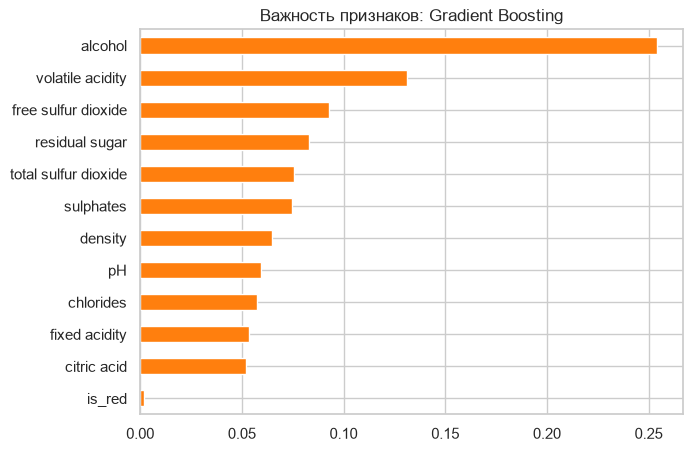

alcohol                 0.254
volatile acidity        0.131
free sulfur dioxide     0.093
residual sugar          0.083
total sulfur dioxide    0.075
sulphates               0.074
density                 0.065
pH                      0.060
chlorides               0.057
fixed acidity           0.053
citric acid             0.052
is_red                  0.002
dtype: float64


In [24]:
imp_gb = pd.Series(gb.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 5))
imp_gb.plot(kind='barh', color='tab:orange')
plt.title('Важность признаков: Gradient Boosting')
plt.show()

print(imp_gb.sort_values(ascending=False).round(3))

**Вывод:** у бустинга `alcohol` тоже на первом месте, и обычно его важность ещё больше, чем у леса.
Причина в том, что бустинг строит деревья последовательно и «жадно» берёт самый информативный признак,
а в случайном лесе из-за `max_features='sqrt'` деревьям часто недоступен `alcohol`, и они вынуждены использовать
похожие признаки (`density`) — поэтому важность в лесу распределена равномернее.
Набор топ-признаков у двух моделей в целом похож.

## 7. Сравнение моделей

In [25]:
res = pd.DataFrame(results).drop_duplicates('Модель', keep='last')
res = res.sort_values('RMSE').reset_index(drop=True)
base_rmse = res.loc[res['Модель'] == 'Baseline (среднее)', 'RMSE'].values[0]
res['Лучше бейзлайна'] = res['RMSE'] < base_rmse
res.round(4)

,Модель,RMSE,MAE,Лучше бейзлайна
0,Random Forest,0.5932,0.4247,True
1,Gradient Boosting,0.6297,0.4760,True
2,Linear Regression,0.7280,0.5678,True
3,Baseline (среднее),0.8738,0.6861,False


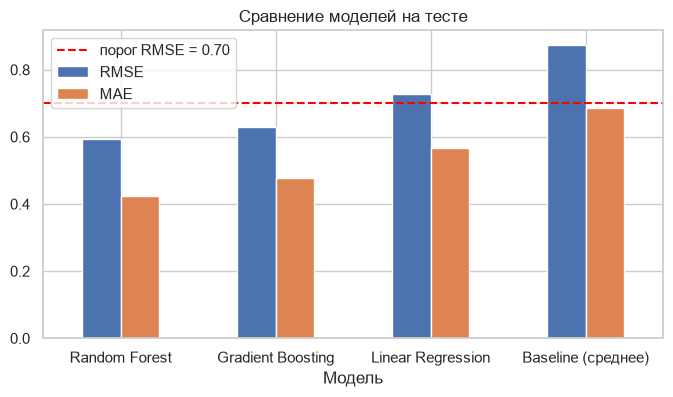

In [26]:
res_plot = res.set_index('Модель')[['RMSE', 'MAE']]
res_plot.plot(kind='bar', figsize=(8, 4), rot=0)
plt.axhline(0.70, color='red', linestyle='--', label='порог RMSE = 0.70')
plt.legend()
plt.title('Сравнение моделей на тесте')
plt.show()

**Вывод:**
- Все модели сравниваются честно: одно и то же разбиение, один и тот же test, одни и те же метрики.
- Все три модели лучше бейзлайна.
- Линейная регрессия улучшает бейзлайн несильно и **не проходит порог 0.70**: зависимость качества от признаков
  нелинейная (например, качество перестаёт расти после какого-то уровня алкоголя, есть взаимодействия признаков),
  а линейная модель может провести только «плоскость».
- Модели на деревьях находят нелинейности и взаимодействия, поэтому ошибаются меньше.
- **Лучшая модель — случайный лес** (в моём запуске у него самая маленькая RMSE, ниже 0.70).
  Бустинг близок к нему. Лесу помогает то, что он хорошо «запоминает» похожие объекты, а в данных много
  очень похожих вин (и даже дубликатов), плюс усреднение 300 глубоких деревьев хорошо снижает разброс.
- У всех моделей RMSE заметно больше MAE — значит, есть отдельные крупные ошибки (см. анализ ошибок).

## 8. Важность признаков: сравнение

Сведу вместе: корреляцию с целевой (EDA), модуль коэффициента линейной регрессии и важности деревьев.

In [27]:
imp_table = pd.DataFrame({
    '|корреляция| (EDA)': corr['quality'].drop('quality').abs(),
    '|коэф. LR|': coefs.abs(),
    'важность RF': imp_rf,
    'важность GB': imp_gb,
})
# нормирую столбцы, чтобы сумма была 1 и их можно было сравнивать
imp_norm = imp_table / imp_table.sum()
imp_norm = imp_norm.sort_values('важность RF', ascending=False)
imp_norm.round(3)

,|корреляция| (EDA),|коэф. LR|,важность RF,важность GB
alcohol,0.263,0.143,0.176,0.254
volatile acidity,0.157,0.136,0.110,0.131
density,0.181,0.181,0.107,0.065
free sulfur dioxide,0.033,0.048,0.085,0.093
chlorides,0.119,0.012,0.083,0.057
total sulfur dioxide,0.024,0.051,0.079,0.075
residual sugar,0.022,0.173,0.076,0.083
sulphates,0.023,0.061,0.075,0.074
citric acid,0.051,0.008,0.072,0.052
pH,0.012,0.049,0.070,0.060


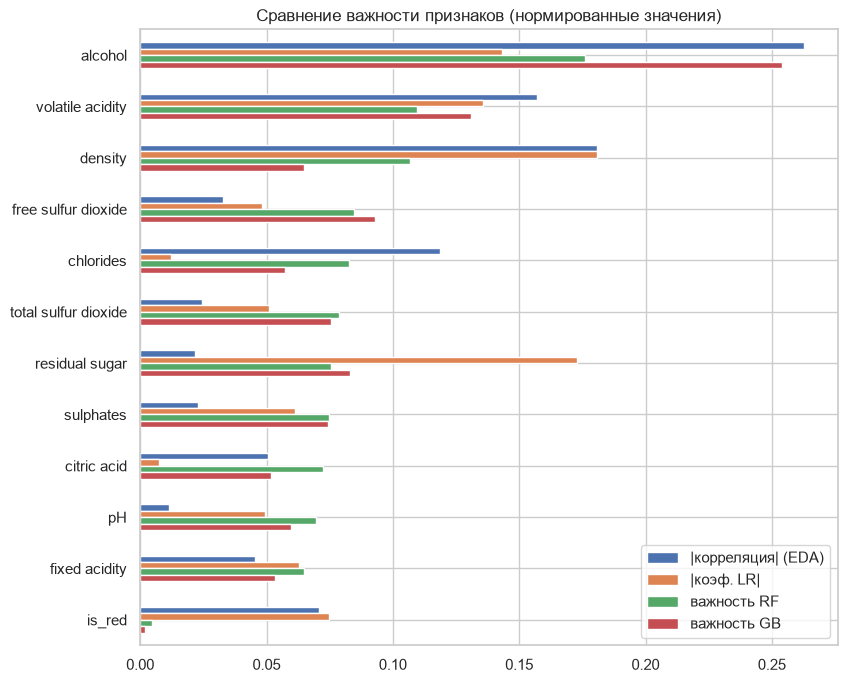

Топ-5 признаков:
|корреляция| (EDA)    : ['alcohol', 'density', 'volatile acidity', 'chlorides', 'is_red']
|коэф. LR|            : ['density', 'residual sugar', 'alcohol', 'volatile acidity', 'is_red']
важность RF           : ['alcohol', 'volatile acidity', 'density', 'free sulfur dioxide', 'chlorides']
важность GB           : ['alcohol', 'volatile acidity', 'free sulfur dioxide', 'residual sugar', 'total sulfur dioxide']


In [28]:
imp_norm.plot(kind='barh', figsize=(9, 8))
plt.gca().invert_yaxis()
plt.title('Сравнение важности признаков (нормированные значения)')
plt.show()

print('Топ-5 признаков:')
for col in imp_norm.columns:
    print(f'{col:22s}:', list(imp_norm[col].sort_values(ascending=False).index[:5]))

**Выводы:**
- **`alcohol`** — самый важный признак почти по всем способам, это совпадает с выводом EDA.
- `volatile acidity` и `density` тоже стабильно в топе — они же имели заметную корреляцию с качеством в EDA.
- Сильнее всего отличается линейная регрессия: у неё большие веса у `density` и `residual sugar` из-за мультиколлинеарности,
  хотя у `residual sugar` корреляция с качеством почти нулевая.
- Деревья могут считать важными признаки с маленькой корреляцией (например, `free sulfur dioxide`),
  потому что зависимость от них нелинейная (плохо и когда сульфитов слишком мало, и когда слишком много),
  а корреляция Пирсона такую связь не видит.

**Означает ли важность признака причинно-следственную связь? Нет.**
Важность показывает только то, насколько модель *использует* признак для предсказания на этих данных.
Например, `density` важна, но плотность сама по себе не делает вино вкуснее — она просто зависит от алкоголя и сахара.
Также важность у коррелированных признаков «делится» между ними, а важность в деревьях (по уменьшению MSE) может
завышать значение признаков с большим количеством уникальных значений. Чтобы говорить о причинах, нужен эксперимент
(например, менять содержание алкоголя при прочих равных), а не просто модель на наблюдательных данных.

## 9. Анализ ошибок лучшей модели

Беру модель с наименьшей RMSE на тесте (у меня это случайный лес) и анализирую её ошибки.

In [29]:
best_name = res.loc[res['Модель'] != 'Baseline (среднее)', 'Модель'].iloc[0]
preds = {'Linear Regression': y_pred_lr, 'Random Forest': y_pred_rf, 'Gradient Boosting': y_pred_gb}
print('Лучшая модель:', best_name)

errors = pd.DataFrame({'true': y_test.values, 'pred': preds[best_name]}, index=y_test.index)
errors['error'] = errors['pred'] - errors['true']
errors['abs_error'] = errors['error'].abs()
errors['error'].describe()

Лучшая модель: Random Forest


count    1300.000000
mean        0.038726
std         0.592156
min        -2.356667
25%        -0.256667
50%         0.030000
75%         0.336667
max         2.643333
Name: error, dtype: float64

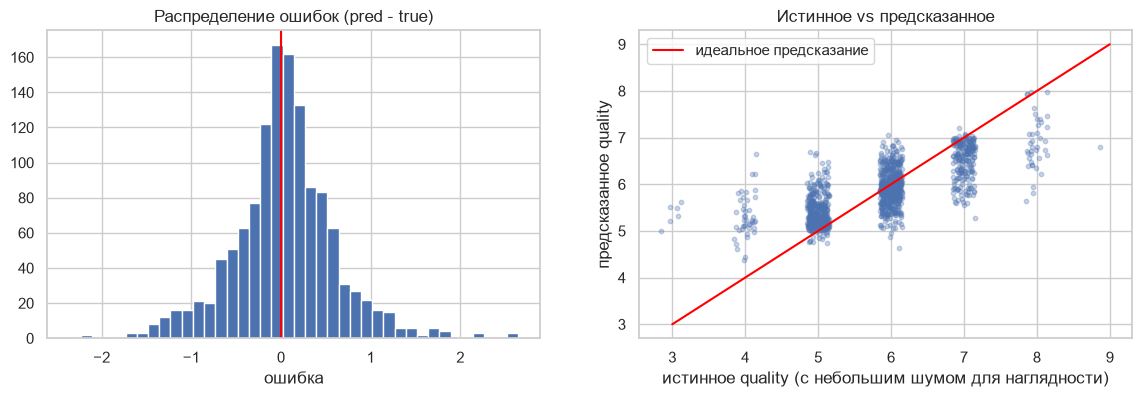

Доля предсказаний с ошибкой меньше 0.5: 0.685
Доля предсказаний с ошибкой больше 1: 0.099


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(errors['error'], bins=40)
axes[0].axvline(0, color='red')
axes[0].set_title('Распределение ошибок (pred - true)')
axes[0].set_xlabel('ошибка')

axes[1].scatter(errors['true'] + np.random.uniform(-0.15, 0.15, len(errors)), errors['pred'], alpha=0.3, s=10)
axes[1].plot([3, 9], [3, 9], color='red', label='идеальное предсказание')
axes[1].set_xlabel('истинное quality (с небольшим шумом для наглядности)')
axes[1].set_ylabel('предсказанное quality')
axes[1].set_title('Истинное vs предсказанное')
axes[1].legend()
plt.show()

print('Доля предсказаний с ошибкой меньше 0.5:', round((errors['abs_error'] < 0.5).mean(), 3))
print('Доля предсказаний с ошибкой больше 1:', round((errors['abs_error'] > 1).mean(), 3))

**Вывод:** ошибки распределены примерно симметрично вокруг нуля, большинство ошибок меньше 0.5 балла.
Но есть «хвосты» — несколько объектов с ошибкой больше 1.5–2 баллов, они и делают RMSE больше MAE.
На графике «истинное vs предсказанное» видно, что точки «сплющены» к середине: для вин с оценкой 3–4
модель предсказывает больше, чем надо, а для вин с оценкой 8–9 — меньше. Модель тянет предсказания к среднему (~5.8).

In [31]:
by_q = errors.groupby('true').agg(
    count=('error', 'size'),
    mean_pred=('pred', 'mean'),
    mean_error=('error', 'mean'),
    MAE=('abs_error', 'mean'),
    RMSE=('error', lambda e: np.sqrt((e ** 2).mean()))
)
by_q.round(3)

,count,mean_pred,mean_error,MAE,RMSE
true,,,,,
3,6,5.358,2.358,2.358,2.368
4,43,5.313,1.313,1.313,1.390
5,428,5.377,0.377,0.387,0.506
6,567,5.942,-0.058,0.293,0.379
7,216,6.518,-0.482,0.486,0.629
8,39,6.907,-1.093,1.093,1.234
9,1,6.790,-2.210,2.210,2.210


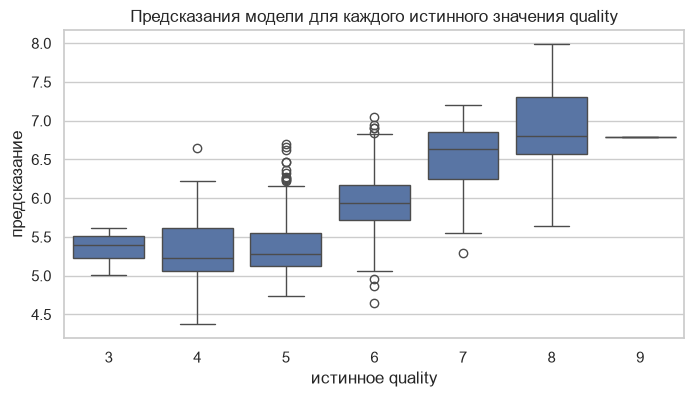

In [32]:
plt.figure(figsize=(8, 4))
sns.boxplot(x='true', y='pred', data=errors)
plt.title('Предсказания модели для каждого истинного значения quality')
plt.xlabel('истинное quality')
plt.ylabel('предсказание')
plt.show()

**Вывод по качеству предсказаний для разных оценок:**
- Для частых оценок **5, 6, 7** ошибка маленькая — на них модель обучалась больше всего.
- Для редких оценок (**3, 4, 8, 9**) ошибка намного больше, а средняя ошибка (`mean_error`) имеет явный знак:
  для 3–4 положительная (модель завышает), для 8–9 отрицательная (модель занижает).

**Почему редкие значения предсказываются хуже:**
1. Примеров очень мало (единицы и десятки), модели не на чем выучить, чем отличаются такие вина.
2. Модель минимизирует MSE по всей выборке, поэтому ей «выгоднее» хорошо предсказывать частые оценки 5–6,
   а при сомнениях выдавать значения ближе к среднему.
3. Случайный лес усредняет ответы деревьев, а среднее не может быть больше максимума обучающих значений в листьях —
   поэтому крайние оценки (3 и 9) получить почти невозможно.
4. По признакам редкие вина часто не сильно отличаются от обычных (boxplot'ы в EDA пересекаются).

In [33]:
X_test_err = X_test.copy()
X_test_err['true'] = errors['true']
X_test_err['pred'] = errors['pred'].round(2)
X_test_err['abs_error'] = errors['abs_error'].round(2)

top_err = X_test_err.sort_values('abs_error', ascending=False).head(10)
top_err[['true', 'pred', 'abs_error', 'alcohol', 'volatile acidity', 'density',
         'free sulfur dioxide', 'sulphates', 'is_red']]

,true,pred,abs_error,alcohol,volatile acidity,density,free sulfur dioxide,sulphates,is_red
6107,4,6.64,2.64,11.5,0.260,0.99020,75.0,0.38,0
2339,3,5.62,2.62,12.6,0.390,0.99150,5.0,0.37,0
1850,3,5.52,2.52,9.8,0.260,0.99800,41.0,0.50,0
3287,3,5.49,2.49,9.4,0.250,0.99490,118.5,0.63,0
3005,8,5.64,2.36,10.5,0.220,0.99440,12.0,0.38,0
1374,3,5.31,2.31,9.8,0.815,0.99471,16.0,0.51,1
5369,4,6.22,2.22,12.0,0.270,0.99094,15.0,0.65,0
2426,9,6.79,2.21,12.5,0.240,0.99055,27.0,0.48,0
3715,4,6.21,2.21,11.7,0.200,0.99020,19.0,0.37,0
1403,8,5.80,2.20,10.0,0.330,0.99600,3.0,1.10,1


In [34]:
# для сравнения: средние значения признаков для каждой оценки на train
train_means = X_train.assign(quality=y_train).groupby('quality')[
    ['alcohol', 'volatile acidity', 'density', 'free sulfur dioxide', 'sulphates']].mean()
train_means.round(3)

,alcohol,volatile acidity,density,free sulfur dioxide,sulphates
quality,,,,,
3,10.252,0.521,0.996,40.333,0.505
4,10.163,0.450,0.995,20.509,0.501
5,9.830,0.392,0.996,30.354,0.527
6,10.568,0.314,0.995,31.103,0.534
7,11.365,0.288,0.993,30.375,0.547
8,11.634,0.284,0.992,35.123,0.503
9,12.100,0.312,0.992,35.000,0.462


**Разбор нескольких больших ошибок** (сравниваю признаки из таблицы выше со средними значениями по оценкам на train):
- Многие самые большие ошибки — это вина с истинной оценкой **3–4 или 8**, т.е. как раз редкие классы.
- Если у вина с низкой оценкой (3–4) при этом **высокий алкоголь и невысокая летучая кислотность**, то по признакам
  оно «выглядит» как хорошее вино, и модель ставит ему 5.5–6. Видимо, его плохую оценку определило что-то,
  чего нет в данных (вкус, дефект, мнение конкретного дегустатора).
- И наоборот, вино с оценкой 8 с **невысоким алкоголем** выглядит как среднее, и модель предсказывает ~6.
- Также оценки ставили люди-эксперты, поэтому в целевой переменной есть «шум»: похожие по химии вина могли получить разные оценки.

Таким образом, крупные ошибки в основном связаны с нетипичными винами, у которых признаки не соответствуют оценке.

## 10. Итоговые выводы

1. **Данные:** 6497 вин (красные + белые), 11 физико-химических признаков + добавленный `is_red`, пропусков нет.
   Целевая переменная `quality` сильно несбалансирована: в основном оценки 5–7.
2. **EDA:** сильнее всего с качеством связан `alcohol` (положительно), затем `density`, `volatile acidity`, `chlorides`
   (отрицательно). Между признаками есть мультиколлинеарность (`density` ~ `alcohol` + `residual sugar`).
3. **Разбиение:** 80/20, `random_state=42`, со стратификацией по `quality`. Все выборы параметров — по кросс-валидации
   на train, test использован только для финальной оценки. Scaler обучается внутри `Pipeline` только на train.
4. **Бейзлайн** (среднее по train) даёт RMSE ≈ 0.87.
5. **Модели:** линейная регрессия лучше бейзлайна, но не проходит порог; модели на деревьях дают RMSE ниже 0.70.
   Лучшая модель — **Random Forest**.
6. **Важность признаков:** во всех моделях на первом месте `alcohol`, что совпадает с EDA. Важность ≠ причинность.
7. **Ошибки:** модель хорошо предсказывает частые оценки 5–7, но тянет редкие оценки (3–4 и 8–9) к среднему.
   Чтобы это улучшить, можно было бы попробовать больше данных по редким оценкам или веса для редких объектов.

### Финальная модель

Для предсказаний на скрытом тесте использую лучшую модель с выбранными параметрами.
Гиперпараметры выбирались без участия теста, поэтому можно дообучить её на всех имеющихся данных (train + test) —
данных станет больше, а модель — немного точнее.

In [35]:
from sklearn.base import clone

models = {'Linear Regression': lr, 'Random Forest': rf, 'Gradient Boosting': gb}
final_model = clone(models[best_name])   # та же модель с теми же параметрами, но ещё не обученная
final_model.fit(X, y)
print('Финальная модель:', best_name)

# пример: предсказание для новых данных с теми же столбцами, что и X
# X_hidden = ...   (данные должны иметь те же признаки, включая is_red)
# y_hidden_pred = final_model.predict(X_hidden[X.columns])
print('Финальная модель обучена на', X.shape[0], 'объектах')

Финальная модель: Random Forest
Финальная модель обучена на 6497 объектах
